# 01 — ETL, partição e versionamento dos dados

**Frente:** Dev 1 · **Critérios:** 1 (dados), 2 (pré-processamento sem vazamento), 9 (versionamento)

Este notebook roda a cada ciclo do pipeline:

1. **Diagnóstico antes**: lotes brutos de `data/raw` (ausentes, duplicados, constantes, outliers, balanceamento).
2. **ETL** (`src/ingestao.py` + `src/preprocessamento.py`): ingestão incremental, deduplicação por `Address`, `data_version`, limpeza e partição fixa por hash do `Address` (60/20/20).
3. **Diagnóstico depois**: tamanho e proporção de fraude por partição, ausência de sobreposição e efeito do pré-processamento ajustado só no treino.
4. **MLflow**: `data_version`, contagens e artefatos (`schema.json`, `lotes.json`) com as tags `cycle_id` e `data_version`.

In [1]:
import os, sys, json
from pathlib import Path

# funciona tanto rodando de notebooks/ (nbconvert) quanto da raiz
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(RAIZ)
sys.path.insert(0, str(RAIZ))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import mlflow

from src.ingestao import carregar_config, ler_registro
from src.preprocessamento import (executar_etl, carregar_particoes, carregar_schema,
                                  montar_preprocessador, PARTICOES, ID, ALVO, LOTE)

cfg = carregar_config()

# cycle_id: vem do workflow (variável CYCLE_ID); fallback local
try:
    from src.rastreio import obter_cycle_id  # helper do Dev 4, quando existir
    CYCLE_ID = obter_cycle_id()
except ImportError:
    from datetime import datetime
    CYCLE_ID = os.getenv("CYCLE_ID") or datetime.now().strftime("%Y%m%d-%H%M") + "-local"
print("cycle_id:", CYCLE_ID)
pd.set_option("display.max_columns", 60)

cycle_id: 20261124-2138-r6


## 1. Diagnóstico antes — lotes brutos

In [2]:
arquivos = sorted((RAIZ / cfg["dados"]["dir_raw"]).glob(cfg["dados"]["padrao_lotes"]))
bruto = pd.concat([pd.read_csv(a).assign(_lote=a.stem) for a in arquivos], ignore_index=True)
alvo = cfg["dados"]["alvo"]

print("lotes:", [a.name for a in arquivos])
print("formato:", bruto.shape)
print("colunas com espaço no início/fim do nome:", sum(c != c.strip() for c in bruto.columns))
print("Address duplicados:", int(bruto["Address"].str.lower().duplicated().sum()))
print("linhas idênticas (fora Index):",
      int(bruto.drop(columns=["Unnamed: 0", "Index", "_lote"], errors="ignore").duplicated().sum()))
bruto.groupby("_lote")[alvo].agg(linhas="size", fraudes="sum", taxa_fraude="mean").round(4)

lotes: ['lote_01.csv']
formato: (6888, 52)
colunas com espaço no início/fim do nome: 26
Address duplicados: 10
linhas idênticas (fora Index): 8


,linhas,fraudes,taxa_fraude
_lote,,,
lote_01,6888,1525,0.2214


In [3]:
ausentes = bruto.isna().sum()
ausentes = ausentes[ausentes > 0].sort_values(ascending=False).to_frame("ausentes")
ausentes["%"] = (ausentes["ausentes"] / len(bruto) * 100).round(2)
print(f"{len(ausentes)} colunas com ausentes")
ausentes

25 colunas com ausentes


,ausentes,%
ERC20 most sent token type,1885,27.37
ERC20_most_rec_token_type,614,8.91
ERC20 total ether sent,584,8.48
ERC20 total Ether received,584,8.48
ERC20 uniq sent addr,584,8.48
ERC20 uniq rec addr,584,8.48
ERC20 uniq sent addr.1,584,8.48
ERC20 total Ether sent contract,584,8.48
Total ERC20 tnxs,584,8.48
ERC20 avg time between sent tnx,584,8.48


**Ausentes e classe.** Os ausentes das colunas ERC20 aparecem juntos, na mesma linha, e **só em carteiras fraudulentas**.
Isso indica um artefato de coleta do dataset, não um comportamento real. Por isso **não** criamos um indicador de
ausência (seria um atalho espúrio para o modelo); os valores são imputados pela mediana do treino. Essa limitação vai para o relatório.

In [4]:
col_erc20 = [c for c in bruto.columns if "ERC20" in c and bruto[c].dtype != object][0]
bruto.assign(erc20_ausente=bruto[col_erc20].isna()).groupby(alvo)["erc20_ausente"].mean().rename("proporção com ERC20 ausente").to_frame()

,proporção com ERC20 ausente
FLAG,
0,0.000000
1,0.382951


In [5]:
num = bruto.select_dtypes("number").drop(columns=["Unnamed: 0", "Index", alvo], errors="ignore")
cat = bruto.select_dtypes(exclude="number").drop(columns=["Address", "_lote"])
print("constantes (<=1 valor distinto):", [c.strip() for c in num.columns if num[c].nunique() <= 1])
print("\ncategóricas:")
for c in cat.columns:
    print(f"  {c.strip()!r}: {cat[c].nunique()} valores distintos; top:",
          cat[c].value_counts().head(4).to_dict())

constantes (<=1 valor distinto): ['ERC20 avg time between sent tnx', 'ERC20 avg time between rec tnx', 'ERC20 avg time between rec 2 tnx', 'ERC20 avg time between contract tnx', 'ERC20 min val sent contract', 'ERC20 max val sent contract', 'ERC20 avg val sent contract']

categóricas:
  'ERC20 most sent token type': 260 valores distintos; top: {'0': 3082, ' ': 835, 'OmiseGO': 99, 'blockwell.ai KYC Casper Token': 93}
  'ERC20_most_rec_token_type': 376 valores distintos; top: {'0': 3082, 'OmiseGO': 610, 'Blockwell say NOTSAFU': 546, 'DATAcoin': 241}


**Outliers.** As variáveis monetárias e de contagem têm cauda muito pesada. Contamos pontos fora de 1,5×IQR e a assimetria:

In [6]:
q1, q3 = num.quantile(0.25), num.quantile(0.75)
iqr = q3 - q1
fora = ((num < q1 - 1.5 * iqr) | (num > q3 + 1.5 * iqr)).sum()
outl = pd.DataFrame({"% fora 1.5×IQR": (fora / len(num) * 100).round(1),
                     "assimetria": num.skew().round(1)})
outl.index = outl.index.str.strip()
outl.sort_values("assimetria", ascending=False).head(12)

,% fora 1.5×IQR,assimetria
avg val received,14.8,81.3
ERC20 min val sent,7.9,79.4
ERC20 max val sent,15.0,79.4
ERC20 avg val sent,14.9,79.4
ERC20 total ether sent,15.9,79.3
ERC20 avg val rec,19.9,76.3
min val sent,14.5,71.3
min value sent to contract,0.0,66.8
total ether sent contracts,0.0,66.0
max val sent to contract,0.0,66.0


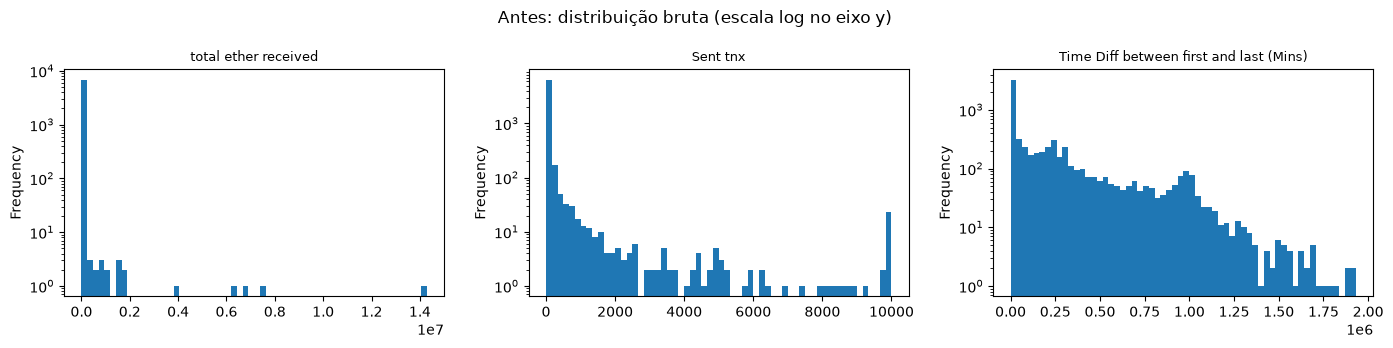

In [7]:
cols_plot = ["total ether received", "Sent tnx", "Time Diff between first and last (Mins)"]
fig_antes, axes = plt.subplots(1, 3, figsize=(14, 3.5))
for ax, c in zip(axes, cols_plot):
    num[c].plot.hist(bins=60, ax=ax, log=True)
    ax.set_title(c, fontsize=9)
fig_antes.suptitle("Antes: distribuição bruta (escala log no eixo y)")
plt.tight_layout(); plt.show()

## 2. ETL — ingestão, limpeza, partição e versionamento

In [8]:
registro_antes = ler_registro(cfg)
print("data_version anterior:", registro_antes.get("data_version"))

resumo = executar_etl(cfg, cycle_id=CYCLE_ID)
schema = carregar_schema(cfg)
DATA_VERSION = resumo["data_version"]

print("data_version atual:  ", DATA_VERSION)
print("lotes incluídos:     ", resumo["lotes"], "| novos neste ciclo:", resumo["lotes_novos"])
print("duplicados removidos:", resumo["duplicados_removidos"])
print("features finais:     ", resumo["n_features"])

data_version anterior: v1-65ada979
data_version atual:   v1-65ada979
lotes incluídos:      ['lote_01'] | novos neste ciclo: []
duplicados removidos: 10
features finais:      38


In [9]:
pd.Series(schema["descartadas"], name="motivo").to_frame()

,motivo
Unnamed: 0,identificador/índice
Index,identificador/índice
Address,identificador/índice
ERC20 most sent token type,categórica de alta cardinalidade
ERC20_most_rec_token_type,categórica de alta cardinalidade
erc20_avg_time_between_sent_tnx,constante no treino
erc20_avg_time_between_rec_tnx,constante no treino
erc20_avg_time_between_rec_2_tnx,constante no treino
erc20_avg_time_between_contract_tnx,constante no treino
erc20_min_val_sent_contract,constante no treino


## 3. Diagnóstico depois — partições

In [10]:
treino, validacao, teste = carregar_particoes(cfg)
partes = dict(zip(PARTICOES, (treino, validacao, teste)))

tab = pd.DataFrame({n: {"linhas": len(p), "fraudes": int(p[ALVO].sum()),
                        "taxa_fraude": round(p[ALVO].mean(), 4),
                        "% do total": round(len(p) / resumo["linhas"] * 100, 1)}
                    for n, p in partes.items()}).T
tab

,linhas,fraudes,taxa_fraude,% do total
treino,4205.0,946.0,0.2250,61.1
validacao,1306.0,271.0,0.2075,19.0
teste,1367.0,308.0,0.2253,19.9


In [11]:
# proporção de fraude por partição × lote: o lote novo se espalha pelas 3 partições
pd.concat([p.assign(particao=n) for n, p in partes.items()]) \
  .pivot_table(index="particao", columns=LOTE, values=ALVO, aggfunc=["size", "mean"]).round(3)

,size,mean
lote,lote_01,lote_01
particao,,
teste,1367,0.225
treino,4205,0.225
validacao,1306,0.208


In [12]:
ends = {n: set(p[ID]) for n, p in partes.items()}
sobreposicao = {f"{a}∩{b}": len(ends[a] & ends[b])
                for i, a in enumerate(PARTICOES) for b in PARTICOES[i + 1:]}
print("sobreposição de endereços entre partições:", sobreposicao)
assert sum(sobreposicao.values()) == 0, "vazamento: endereço em mais de uma partição"
print("ausentes restantes (imputados no Pipeline):", int(treino[schema["features"]].isna().sum().sum()), "no treino")

sobreposição de endereços entre partições: {'treino∩validacao': 0, 'treino∩teste': 0, 'validacao∩teste': 0}
ausentes restantes (imputados no Pipeline): 5824 no treino


**Pré-processamento sem vazamento.** `montar_preprocessador` devolve um `ColumnTransformer` **não ajustado**
(log com sinal → imputer mediana → `StandardScaler`). Ele é ajustado **só no treino**, e o Dev 3 o coloca dentro do `Pipeline`
de cada modelo. Aqui só conferimos o efeito: no treino média ≈ 0 e desvio ≈ 1; na validação os valores ficam próximos, mas não exatos,
o que mostra que nada da validação entrou no ajuste.

In [13]:
pre = montar_preprocessador(schema["features"], cfg).fit(treino)
xt, xv = pre.transform(treino), pre.transform(validacao)
pd.DataFrame({"média treino": xt.mean().round(3), "desvio treino": xt.std().round(3),
              "média validação": xv.mean().round(3), "desvio validação": xv.std().round(3)}).head(10)

,média treino,desvio treino,média validação,desvio validação
avg_min_between_sent_tnx,0.0,1.0,-0.018,0.982
avg_min_between_received_tnx,0.0,1.0,-0.025,1.007
time_diff_between_first_and_last_mins,0.0,1.0,-0.018,1.021
sent_tnx,0.0,1.0,0.020,1.027
received_tnx,0.0,1.0,0.014,1.012
number_of_created_contracts,-0.0,1.0,0.032,1.349
unique_received_from_addresses,-0.0,1.0,-0.038,0.930
unique_sent_to_addresses,-0.0,1.0,-0.002,0.980
min_value_received,-0.0,1.0,0.015,1.004
max_value_received,0.0,1.0,0.012,0.997


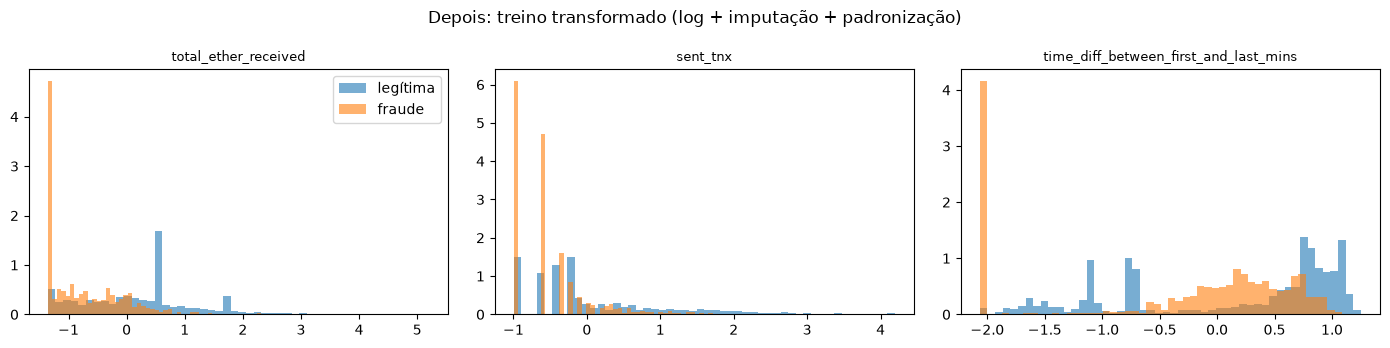

In [14]:
cols_plot_n = ["total_ether_received", "sent_tnx", "time_diff_between_first_and_last_mins"]
fig_depois, axes = plt.subplots(1, 3, figsize=(14, 3.5))
for ax, c in zip(axes, cols_plot_n):
    for rot, g in xt.groupby(treino[ALVO].values):
        ax.hist(g[c], bins=50, alpha=0.6, label="fraude" if rot == 1 else "legítima", density=True)
    ax.set_title(c, fontsize=9)
axes[0].legend()
fig_depois.suptitle("Depois: treino transformado (log + imputação + padronização)")
plt.tight_layout(); plt.show()

## 4. Registro no MLflow

In [15]:
# helper do Dev 4: mlflow.db na raiz e artefatos em mlartifacts/ (persistidos pelo workflow)
from src.rastreio import configurar_mlflow
configurar_mlflow(cfg)

with mlflow.start_run(run_name=f"etl-{CYCLE_ID}",
                      tags={"cycle_id": CYCLE_ID, "data_version": DATA_VERSION, "etapa": "etl"}) as run:
    mlflow.log_params({
        "data_version": DATA_VERSION,
        "lotes": ",".join(resumo["lotes"]),
        "lotes_novos": ",".join(resumo["lotes_novos"]) or "nenhum",
        "particao": "hash_md5_address 60/20/20",
        "n_features": resumo["n_features"],
        "seed": cfg["seeds"]["global"],
    })
    mlflow.log_metrics({
        "linhas_brutas": resumo["linhas_brutas"],
        "duplicados_removidos": resumo["duplicados_removidos"],
        "linhas": resumo["linhas"],
        **{f"{n}_linhas": v["linhas"] for n, v in resumo["particoes"].items()},
        **{f"{n}_taxa_fraude": v["taxa_fraude"] for n, v in resumo["particoes"].items()},
    })
    proc = RAIZ / cfg["dados"]["dir_processed"]
    mlflow.log_artifact(str(proc / "schema.json"), "dados")
    mlflow.log_artifact(str(proc / "lotes.json"), "dados")
    mlflow.log_text(ausentes.to_csv(), "dados/ausentes_antes.csv")
    mlflow.log_text(outl.to_csv(), "dados/outliers_antes.csv")
    mlflow.log_figure(fig_antes, "dados/distribuicao_antes.png")
    mlflow.log_figure(fig_depois, "dados/distribuicao_depois.png")
    print("run_id:", run.info.run_id)

run_id: 1f8576955ef34eccac09a05952afccda


### Entregas para as outras frentes
- **Partições:** `data/processed/{treino,validacao,teste}.parquet` (colunas `address`, `lote`, `flag` + features)
- **Lista de features:** `carregar_schema()["features"]`
- **Pré-processamento:** `montar_preprocessador(features)`, a ser ajustado só no treino dentro do `Pipeline`
- **Versão dos dados:** `DATA_VERSION`, também em `data/processed/lotes.json`